# Entrega 1 — Análise Comparativa de Representações
### Desafio 1 · Ouvidoria Inteligente: Triagem Semântica de Manifestações Cidadãs

Processamento de Linguagem Natural / Engenharia de IA · Maria Eduarda

Comparação entre representações esparsas (BoW, TF-IDF) e densas (embeddings) na tarefa de similaridade
semântica entre manifestações cidadãs, avaliada sobre os pares M003×M017, M008×M022 e M008×M031.

## 1. Configuração e Carga dos Dados

In [1]:
!pip install -q sentence-transformers scikit-learn pandas numpy matplotlib

In [2]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option("display.max_colwidth", 250)
pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 110

In [3]:
CAMINHO_JSON = "manifestacoes.json"

# Pares definidos no enunciado
PARES = [("M003", "M017"), ("M008", "M022"), ("M008", "M031")]
PAPEL_DO_PAR = {
    ("M003", "M017"): "Mesmo problema (buraco na avenida), palavras diferentes",
    ("M008", "M022"): "Mesmo tema (saúde), palavras diferentes",
    ("M008", "M031"): "Controle: temas sem relação (saúde x iluminação)",
}

# O enunciado sugere paraphrase-multilingual-MiniLM-L12-v2 ou BAAI/bge-small-pt-v1.5.
# Este último não existe publicamente no Hugging Face (só há versões da BGE em inglês
# e chinês); o segundo modelo comparado é outro sentence-transformer multilíngue real.
MODELOS = {
    "MiniLM-L12": "paraphrase-multilingual-MiniLM-L12-v2",
    "DistilUSE": "distiluse-base-multilingual-cased-v2",
}

In [4]:
# Upload do dataset quando executado no Colab
try:
    import google.colab
    from google.colab import files
    if not os.path.exists(CAMINHO_JSON):
        files.upload()
except ImportError:
    pass

In [5]:
with open(CAMINHO_JSON, encoding="utf-8") as f:
    dados = json.load(f)
if isinstance(dados, dict):
    dados = next(v for v in dados.values() if isinstance(v, list))

df = pd.DataFrame(dados)

assert {"id", "texto"} <= set(df.columns)
assert df["id"].is_unique
assert {i for par in PARES for i in par} <= set(df["id"])

df["n_caracteres"] = df["texto"].str.len()
print(f"{len(df)} manifestações carregadas | colunas: {list(df.columns)}")
display(df["n_caracteres"].describe().to_frame("tamanho dos textos (caracteres)").T)
display(df["categoria_oficial"].value_counts().to_frame("qtd"))

40 manifestações carregadas | colunas: ['id', 'data', 'categoria_oficial', 'texto', 'n_caracteres']


,count,mean,std,min,25%,50%,75%,max
tamanho dos textos (caracteres),40.0,177.825,222.4167,55.0,87.5,101.0,109.0,785.0


,qtd
categoria_oficial,
infraestrutura,10
saúde,9
segurança,8
meio ambiente,7
educação,6


## 2. Pares Analisados

In [6]:
posicao = {id_: k for k, id_ in enumerate(df["id"])}

linhas = []
for a, b in PARES:
    for id_ in (a, b):
        linha = df.iloc[posicao[id_]]
        linhas.append({"Par": f"{a} × {b}", "id": id_,
                        "categoria": linha["categoria_oficial"], "texto": linha["texto"]})
display(pd.DataFrame(linhas).set_index(["Par", "id"]))

categoria  \
Par         id                     
M003 × M017 M003  infraestrutura   
            M017  infraestrutura   
M008 × M022 M008           saúde   
            M022           saúde   
M008 × M031 M008           saúde   
            M031  infraestrutura   

                                                                                         texto  
Par         id                                                                                  
M003 × M017 M003  Buraco enorme na Av. Brasil, já causou dois acidentes com motos esta semana.  
            M017             Asfalto todo esburacado da avenida principal, carros danificados.  
M008 × M022 M008                Posto de saúde sem médico há duas semanas, ninguém é atendido.  
            M022          Falta atendimento no PSF do meu bairro, sem médico e sem enfermeira.  
M008 × M031 M008                Posto de saúde sem médico há duas semanas, ninguém é atendido.  
            M031                       Lâmpada queimada na praça deixa o local escuro à noite.

## 3. Representações Esparsas: BoW e TF-IDF

BoW e TF-IDF só reconhecem semelhança quando a mesma string aparece nos dois textos, por isso o
texto é normalizado antes (minúsculas, remoção de acentos e de stopwords). "Sem" e "não" são
mantidos fora da lista de stopwords por carregarem sentido em reclamações ("posto **sem** médico").
Os embeddings, na Seção 4, recebem o texto original. Os dois vetorizadores são ajustados no corpus
completo das 40 manifestações.

In [7]:
STOPWORDS_PT = sorted({w for w in '''
    as os um uma uns umas de do da dos das em no na nos nas num numa por pelo pela pelos pelas para pra
    com sobre entre ate ao aos ou mas que se como ja tambem mais menos muito muitos pouco so ainda entao
    porque pois quando onde qual quais quem eu tu ele ela eles elas voce me te lhe lhes meu minha teu tua
    seu sua seus suas nosso nossa este esta esse essa isto isso aquele aquela aquilo ser sao foi era sido
    ter tem tinha ha estar estao durante apos antes desde depois cada todo toda todos todas outro outra
    outros outras mesmo mesma la aqui ali
'''.split() if len(w) > 1})

PARAMS_LEXICOS = dict(lowercase=True, strip_accents="unicode", stop_words=STOPWORDS_PT)
textos = df["texto"].tolist()

vec_bow = CountVectorizer(**PARAMS_LEXICOS)
X_bow = vec_bow.fit_transform(textos)

vec_tfidf = TfidfVectorizer(**PARAMS_LEXICOS)
X_tfidf = vec_tfidf.fit_transform(textos)

def esparsidade(X):
    return 100 * (1 - X.nnz / (X.shape[0] * X.shape[1]))

display(pd.DataFrame({
    "formato (docs x termos)": [X_bow.shape, X_tfidf.shape],
    "termos no vocabulário": [X_bow.shape[1], X_tfidf.shape[1]],
    "% de zeros na matriz": [esparsidade(X_bow), esparsidade(X_tfidf)],
}, index=["BoW", "TF-IDF"]))

,formato (docs x termos),termos no vocabulário,% de zeros na matriz
BoW,"(40, 480)",480,96.4375
TF-IDF,"(40, 480)",480,96.4375


In [8]:
# IDF: termo comum no corpus (peso baixo) vs. termo raro (peso alto, discriminativo)
termos = np.array(vec_tfidf.get_feature_names_out())
idf = pd.Series(vec_tfidf.idf_, index=termos).sort_values()
display(idf.head(8).to_frame("IDF (menor)").T)
display(idf.tail(8).to_frame("IDF (maior)").T)

,bairro,rua,moradores,sem,municipal,meses,tres,relatam
IDF (menor),2.0745,2.3157,2.411,2.411,2.6341,2.6341,2.7677,2.7677


,ambientalistas,ambiental,alto,alternativa,alta,algo,alagando,agravam
IDF (maior),4.0204,4.0204,4.0204,4.0204,4.0204,4.0204,4.0204,4.0204


## 4. Representações Densas: Embeddings

Cada texto é convertido em um vetor denso por um *sentence-transformer* multilíngue.
Com `normalize_embeddings=True`, o produto escalar entre dois vetores equivale à similaridade de cosseno.

In [9]:
from sentence_transformers import SentenceTransformer

embeddings = {}
for rotulo, nome_modelo in MODELOS.items():
    try:
        modelo = SentenceTransformer(nome_modelo)
        embeddings[rotulo] = modelo.encode(textos, normalize_embeddings=True, show_progress_bar=False)
        print(f"✔ {rotulo} ({nome_modelo}) -> {embeddings[rotulo].shape}")
    except Exception as erro:
        print(f"⚠ Falha ao carregar {rotulo} ({nome_modelo}): {erro}")

assert embeddings, "Nenhum modelo de embedding foi carregado."

/home/milena/Documentos/agroSearch/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2408.62it/s]


✔ MiniLM-L12 (paraphrase-multilingual-MiniLM-L12-v2) -> (40, 384)


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 2855.02it/s]


✔ DistilUSE (distiluse-base-multilingual-cased-v2) -> (40, 512)


## 5. Similaridade de Cosseno nos Pares

In [10]:
representacoes = {"BoW": X_bow, "TF-IDF": X_tfidf}
representacoes.update({f"Embeddings ({r})": M for r, M in embeddings.items()})

def cosseno(M, id_a, id_b):
    a, b = posicao[id_a], posicao[id_b]
    return float(cosine_similarity(M[a:a+1], M[b:b+1])[0, 0])

valores = pd.DataFrame(
    {rotulo: [cosseno(M, a, b) for a, b in PARES] for rotulo, M in representacoes.items()},
    index=[f"{a} × {b}" for a, b in PARES],
)
valores.index.name = "Par"

tabela = valores.copy()
tabela.insert(0, "O que o par representa", [PAPEL_DO_PAR[p] for p in PARES])
display(tabela)

,O que o par representa,BoW,TF-IDF,Embeddings (MiniLM-L12),Embeddings (DistilUSE)
Par,,,,,
M003 × M017,"Mesmo problema (buraco na avenida), palavras diferentes",0.0000,0.0000,0.4217,0.3628
M008 × M022,"Mesmo tema (saúde), palavras diferentes",0.3354,0.2596,0.6608,0.4400
M008 × M031,Controle: temas sem relação (saúde x iluminação),0.0000,0.0000,-0.0310,-0.0123


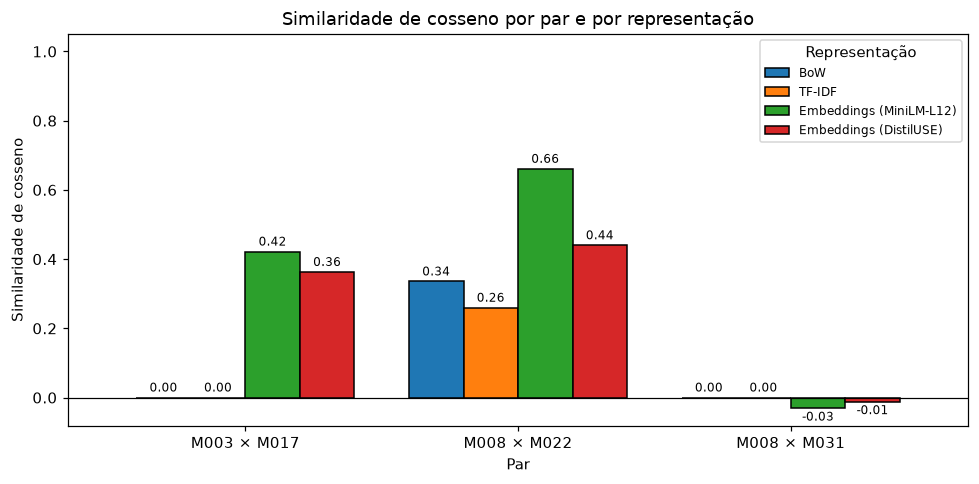

In [11]:
ax = valores.plot(kind="bar", figsize=(9, 4.5), width=0.8, edgecolor="black")
ax.set_ylim(min(0, valores.values.min() - 0.05), 1.05)
ax.set_ylabel("Similaridade de cosseno")
ax.set_title("Similaridade de cosseno por par e por representação")
ax.axhline(0, color="black", linewidth=0.8)
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.2f", fontsize=8, padding=2)
plt.xticks(rotation=0)
plt.legend(title="Representação", loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

## 6. Interpretação dos Resultados

**Termos em comum.** Em BoW/TF-IDF o cosseno só é não nulo quando os dois textos compartilham termos
após o pré-processamento.

In [12]:
analisador = vec_bow.build_analyzer()

linhas = []
for a, b in PARES:
    termos_a = set(analisador(df.iloc[posicao[a]]["texto"]))
    termos_b = set(analisador(df.iloc[posicao[b]]["texto"]))
    comuns = sorted(termos_a & termos_b)
    linhas.append({"Par": f"{a} × {b}", "termos (1º texto)": len(termos_a),
                    "termos (2º texto)": len(termos_b), "em comum": len(comuns),
                    "quais": ", ".join(comuns) if comuns else "— nenhum —"})
display(pd.DataFrame(linhas).set_index("Par"))

,termos (1º texto),termos (2º texto),em comum,quais
Par,,,,
M003 × M017,9,6,0,— nenhum —
M008 × M022,8,7,2,"medico, sem"
M008 × M031,8,7,0,— nenhum —


**Linha de base.** Embeddings tendem a valores moderados mesmo para textos sem relação, enquanto
BoW/TF-IDF ficam perto de 0; por isso cada par é situado no percentil da distribuição de similaridade
de todos os 780 pares possíveis do corpus (empates contam pela metade).

In [13]:
def similaridades_de_todos_os_pares(M):
    S = cosine_similarity(M)
    return S[np.triu_indices_from(S, k=1)]

linha_de_base, percentis = {}, {}
for rotulo, M in representacoes.items():
    todos = similaridades_de_todos_os_pares(M)
    linha_de_base[rotulo] = {"média": todos.mean(), "mediana": np.median(todos), "máximo": todos.max()}
    percentis[rotulo] = [100 * ((todos < cosseno(M, a, b)).mean() + 0.5 * (todos == cosseno(M, a, b)).mean())
                         for a, b in PARES]

display(pd.DataFrame(linha_de_base).T)

tab_percentil = pd.DataFrame(percentis, index=[f"{a} × {b}" for a, b in PARES])
tab_percentil.index.name = "Par"
display(tab_percentil.round(1))

,média,mediana,máximo
BoW,0.0398,0.0000,0.4615
TF-IDF,0.0235,0.0000,0.4183
Embeddings (MiniLM-L12),0.2325,0.2245,0.8351
Embeddings (DistilUSE),0.1732,0.1558,0.6942


,BoW,TF-IDF,Embeddings (MiniLM-L12),Embeddings (DistilUSE)
Par,,,,
M003 × M017,31.2,31.2,88.3,92.5
M008 × M022,99.6,99.7,99.0,97.4
M008 × M031,31.2,31.2,3.8,2.3


In [14]:
# Poder de separação: quanto o par relevante (M008 x M022) supera o par de controle (M008 x M031)
rel, ctrl = "M008 × M022", "M008 × M031"
display((valores.loc[rel] - valores.loc[ctrl]).to_frame("margem (relevante − controle)"))

,margem (relevante − controle)
BoW,0.3354
TF-IDF,0.2596
Embeddings (MiniLM-L12),0.6918
Embeddings (DistilUSE),0.4522


## 7. Discussão

### 7.1 Análise por par

**M003 × M017** (buraco na avenida, descrito com termos distintos) — BoW = 0,00 · TF-IDF = 0,00 ·
Embeddings (MiniLM-L12) = 0,42 · Embeddings (DistilUSE) = 0,36 · termos em comum: 0. Como "buraco"/
"esburacado" e "Av. Brasil"/"avenida principal" não compartilham nenhuma *string* após o
pré-processamento, BoW e TF-IDF atribuem similaridade nula ao par, apesar de os dois textos
descreverem o mesmo problema. Os embeddings capturam essa equivalência semântica mesmo sem
sobreposição lexical: o par fica no percentil 88,2 (MiniLM-L12) e 92,5 (DistilUSE) da distribuição do
corpus — bem acima da mediana de cada modelo (0,22 e 0,16, respectivamente) —, evidenciando o ganho da
representação densa exatamente no cenário em que BoW/TF-IDF falham.

**M008 × M022** (posto de saúde sem médico × falta de atendimento no PSF) — BoW = 0,34 · TF-IDF = 0,26 ·
Embeddings (MiniLM-L12) = 0,66 · Embeddings (DistilUSE) = 0,44. Os termos "médico" e "sem", comuns aos
dois textos, já bastam para que as representações léxicas captem parte da similaridade. É o par com
maior similaridade em todas as representações e o de percentil mais alto em qualquer uma delas (96,4 a
99,7), confirmando que o par soma sobreposição lexical explícita a uma equivalência semântica adicional
— entre a sigla "PSF" e "posto de saúde" — que somente os embeddings capturam integralmente, já que
nenhum modelo lexical reconhece a sigla como sinônimo.

**M008 × M031** (controle: saúde × lâmpada queimada) — BoW = 0,00 · TF-IDF = 0,00 ·
Embeddings (MiniLM-L12) = −0,03 · Embeddings (DistilUSE) = −0,01. Sem termos em comum, BoW e TF-IDF
dão zero, como esperado para um par de controle. Os embeddings retornam valores levemente negativos,
abaixo até da própria mediana do corpus, posicionando o par no percentil 4,0 (MiniLM-L12) e 2,3
(DistilUSE) — entre os pares menos similares de todo o conjunto. Isso indica que os dois modelos
semânticos testados distinguem corretamente temas não relacionados, mesmo quando ambos descrevem
problemas urbanos genéricos.

### 7.2 Limitações de cada abordagem

O **BoW** representa cada manifestação apenas pela contagem de palavras, ignorando ordem e contexto:
termos morfologicamente relacionados ("buraco"/"esburacado") são tratados como independentes, e a
similaridade só emerge de sobreposição literal de vocabulário — no par M003×M017 isso resulta em
similaridade nula para textos que descrevem o mesmo problema, enquanto no par M008×M022 a presença de
apenas dois termos comuns já eleva a similaridade a 0,34. O **TF-IDF** atenua o peso de termos
frequentes no corpus e realça os discriminativos; no par M008×M022 isso reduz a similaridade de 0,34
para 0,26, já que parte da sobreposição vinha de um termo comum ("sem"), mas o método permanece
estritamente lexical, incapaz de conectar sinônimos e siglas como "PSF" e "posto de saúde". Os
**embeddings** superam essa limitação ao capturar relações semânticas mesmo sem sobreposição de
palavras — reconhecendo corretamente o par M003×M017 (percentil 88–93) e separando o par de controle
M008×M031 (percentil 2–4) —, mas têm um custo estrutural: a similaridade média entre pares aleatórios do
corpus já é de 0,17–0,23 (contra 0,02–0,04 em BoW/TF-IDF), o que exige calibrar limiares específicos em
vez de interpretar valores absolutos de cosseno. Entre os dois modelos testados, o MiniLM-L12 apresentou
maior poder de separação entre o par relevante e o de controle (margem de 0,69 contra 0,45 do
DistilUSE), sugerindo maior adequação a esta base. Para a triagem de manifestações da Ouvidoria, uma
abordagem híbrida — sobreposição lexical como sinal complementar e embeddings como representação
principal — tende a equilibrar melhor a precisão em termos técnicos exatos com a cobertura semântica
necessária para agrupar sinônimos e siglas do domínio público.